<a href="https://colab.research.google.com/github/nanditapandey000/Machine-Learning-Model-Development-and-Evaluation/blob/main/week4_ml_model_development_(1).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Week 4 — Machine Learning Model Development & Evaluation

**Dataset:** LendingClub consumer-loan data (Week 1 cleaned, 42,535 loans)
**Objective:** Build, tune, and evaluate machine-learning models for loan-default prediction, comparing four algorithms with cross-validation and hyperparameter optimization.

## Task overview

This notebook addresses the Week 4 assignment:

1. **Algorithm selection** — four classifiers compared: regularized logistic regression (baseline), random forest, XGBoost, LightGBM.
2. **Cross-validation & hyperparameter tuning** — 3-fold stratified CV with `RandomizedSearchCV` (8 iterations per model), optimizing for PR-AUC (appropriate for the 15% class-imbalance).
3. **Evaluation** — ROC-AUC, PR-AUC, accuracy, precision, recall, F1, Brier score, log loss; plus confusion matrices, ROC/PR curves, learning curves, and feature importance.
4. **Interpretation** — discuss model strengths and weaknesses, the calibration drift observed in XGBoost, and the surprising finding that logistic regression edges out the tree ensembles.

> **Reproducibility.** Upload `cleaned_dataset.csv` to the Colab working directory and Run All. All randomness uses `random_state=42`. The full pipeline takes ~7 minutes on a 4-core CPU.

## 1. Environment setup

In [16]:
import warnings
warnings.filterwarnings("ignore")

import json
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.model_selection import (StratifiedKFold, RandomizedSearchCV,
                                      train_test_split, learning_curve)
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (roc_auc_score, average_precision_score,
                             roc_curve, precision_recall_curve,
                             confusion_matrix, classification_report,
                             brier_score_loss, accuracy_score,
                             precision_score, recall_score, f1_score,
                             log_loss)
from sklearn.calibration import calibration_curve

import xgboost as xgb
import lightgbm as lgb
import joblib

sns.set_theme(style="whitegrid", font_scale=1.0)
plt.rcParams["figure.dpi"] = 110
RANDOM_STATE = 42
N_JOBS = -1
np.random.seed(RANDOM_STATE)
print("Environment ready.")

Environment ready.


## 2. Data loading & feature selection

We reuse the Week-1 cleaned dataset. The binary target `is_default` is constructed exactly as in Week 3 (any non-Fully-Paid status).

**Feature engineering decisions:**

- We **drop `int_rate`** because it is downstream of `grade` — including it would leak the credit-grade signal into the default model. The Week-3 analysis showed grade and int_rate are nearly collinear; here we let the model learn the relationship from `grade` directly.
- We **drop `issue_d`, `issue_year`, `issue_month`** to avoid temporal leakage. A production model would respect time-ordering in the train/test split; this notebook uses a stratified random split for simplicity but flags the issue in the limitations.
- We **drop `sub_grade`** (collinear with `grade`), `emp_title` (25k+ unique, too sparse), and the normalized `_minmax`/`_zscore` copies of variables already present in raw form.
- We **engineer `term_months`** (integer term) and **`grade_ord`** (grade on a 1–7 ordinal scale).

In [17]:
df = pd.read_csv("cleaned_dataset.csv")
print(f"Loaded {len(df):,} loans, {df.shape[1]} columns.")

# Construct binary target
default_statuses = ["Charged Off",
                    "Does not meet the credit policy. Status:Charged Off"]
df["is_default"] = df["loan_status"].isin(default_statuses).astype(int)

# Engineered numeric encodings
if df["term"].dtype == object:
    df["term_months"] = df["term"].astype(str).str.extract(r"(\d+)").astype(int)
else:
    df["term_months"] = df["term"]
grade_map = {"A": 1, "B": 2, "C": 3, "D": 4, "E": 5, "F": 6, "G": 7}
df["grade_ord"] = df["grade"].map(grade_map)

# Drop leaky / collinear / high-cardinality columns
drop_cols = [
    "loan_status", "funded_amnt", "funded_amnt_inv", "int_rate",
    "issue_d", "issue_year", "issue_month",
    "emp_title", "sub_grade", "installment",
    # Normalized copies
    "loan_amnt_minmax", "loan_amnt_zscore", "annual_inc_minmax", "annual_inc_zscore",
    "int_rate_minmax", "int_rate_zscore", "installment_minmax", "installment_zscore",
    "dti_minmax", "dti_zscore", "revol_bal_minmax", "revol_bal_zscore",
    "revol_util_minmax", "revol_util_zscore", "credit_history_years_minmax",
    "credit_history_years_zscore", "loan_to_income_minmax", "loan_to_income_zscore",
    "installment_to_income_minmax", "installment_to_income_zscore",
]
df = df.drop(columns=[c for c in drop_cols if c in df.columns], errors="ignore")

print(f"Default rate: {df['is_default'].mean() * 100:.2f}% "
      f"({df['is_default'].sum():,} of {len(df):,})")
print(f"Columns after feature selection: {df.shape[1]}")

Loaded 42,535 loans, 55 columns.
Default rate: 15.12% (6,431 of 42,535)
Columns after feature selection: 28


### 2.1 Feature groups

Numeric features pass through median imputation + standard scaling. Categorical features pass through mode imputation + one-hot encoding. The full feature space after one-hot encoding is 47 columns.

In [18]:
numeric_features = [
    "loan_amnt", "term_months", "annual_inc", "dti",
    "credit_history_years", "inq_last_6mths", "open_acc", "pub_rec",
    "revol_bal", "revol_util", "total_acc",
    "delinq_2yrs", "pub_rec_bankruptcies", "tax_liens",
    "loan_to_income", "installment_to_income", "grade_ord", "emp_length",
]
numeric_features = [c for c in numeric_features if c in df.columns]
categorical_features = ["grade", "home_ownership", "verification_status",
                         "purpose", "addr_state"]
categorical_features = [c for c in categorical_features if c in df.columns]

print(f"Numeric features ({len(numeric_features)}): {numeric_features}")
print(f"Categorical features ({len(categorical_features)}): {categorical_features}")
print(f"Total features after one-hot: {len(numeric_features) + sum(df[c].nunique() for c in categorical_features)}")

Numeric features (18): ['loan_amnt', 'term_months', 'annual_inc', 'dti', 'credit_history_years', 'inq_last_6mths', 'open_acc', 'pub_rec', 'revol_bal', 'revol_util', 'total_acc', 'delinq_2yrs', 'pub_rec_bankruptcies', 'tax_liens', 'loan_to_income', 'installment_to_income', 'grade_ord', 'emp_length']
Categorical features (5): ['grade', 'home_ownership', 'verification_status', 'purpose', 'addr_state']
Total features after one-hot: 97


## 3. Preprocessing pipeline

A single `ColumnTransformer` handles both numeric and categorical features. Wrapping it in a `Pipeline` with the classifier ensures the same preprocessing is applied during cross-validation, preventing leakage.

In [19]:
def build_preprocessor(num, cat):
    num_pipe = Pipeline([
        ("impute", SimpleImputer(strategy="median")),
        ("scale", StandardScaler()),
    ])
    cat_pipe = Pipeline([
        ("impute", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
    ])
    return ColumnTransformer([
        ("num", num_pipe, num),
        ("cat", cat_pipe, cat),
    ], remainder="drop")

# Train/test split (70/30 stratified)
X = df[numeric_features + categorical_features]
y = df["is_default"].astype(int)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=RANDOM_STATE, stratify=y)

print(f"Train: {len(X_train):,} rows, {y_train.sum():,} defaults ({y_train.mean()*100:.2f}%)")
print(f"Test:  {len(X_test):,} rows, {y_test.sum():,} defaults ({y_test.mean()*100:.2f}%)")

Train: 29,774 rows, 4,502 defaults (15.12%)
Test:  12,761 rows, 1,929 defaults (15.12%)


## 4. Algorithm selection & justification

We compare four algorithms spanning three families:

| Algorithm | Family | Why included |
|-----------|--------|--------------|
| **Logistic Regression** | Generalized linear model | Interpretable baseline; L2-regularized to handle multicollinearity from Week 3. `class_weight="balanced"` corrects for the 15% default rate. |
| **Random Forest** | Bagging ensemble | Captures nonlinearities and feature interactions automatically; robust to outliers and scaling; provides feature importance. |
| **XGBoost** | Gradient boosting | State-of-the-art on tabular data; handles missing values natively; L1/L2 regularization built in. |
| **LightGBM** | Gradient boosting (histogram-based) | Faster than XGBoost; leaf-wise growth often yields better AUC; native handling of categorical features. |

The tree ensembles should in principle outperform logistic regression on tabular data with nonlinear feature interactions. We will see whether that holds for this dataset.

## 5. Hyperparameter tuning

We use `RandomizedSearchCV` with **8 iterations per model** and **3-fold stratified cross-validation**. The search optimizes **PR-AUC** (average precision) rather than ROC-AUC or accuracy, because:

* PR-AUC is more sensitive than ROC-AUC to performance on the minority (default) class.
* Accuracy is misleading under class imbalance (a trivial classifier scores 85%).
* The business cost of false negatives (default losses) typically dominates the cost of false positives (lost loan revenue).

A full grid search over these spaces would require 1000+ fits per model; randomized search over 8 iterations gives a good approximation at 1/100th the cost.

In [20]:
def model_specs():
    from collections import OrderedDict
    specs = OrderedDict()

    specs["Logistic Regression"] = (
        LogisticRegression(max_iter=1000, random_state=RANDOM_STATE,
                           class_weight="balanced"),
        {
            "clf__C": stats.loguniform(1e-3, 1e2),
            "clf__penalty": ["l2"],
            "clf__solver": ["lbfgs"],
        },
    )

    specs["Random Forest"] = (
        RandomForestClassifier(random_state=RANDOM_STATE,
                               class_weight="balanced", n_jobs=N_JOBS),
        {
            "clf__n_estimators": [200, 400, 600],
            "clf__max_depth": [8, 12, 16, None],
            "clf__min_samples_leaf": [1, 5, 10],
            "clf__max_features": ["sqrt", "log2"],
        },
    )

    specs["XGBoost"] = (
        xgb.XGBClassifier(
            objective="binary:logistic", eval_metric="aucpr",
            tree_method="hist", random_state=RANDOM_STATE,
            n_jobs=N_JOBS, use_label_encoder=False,
        ),
        {
            "clf__n_estimators": [200, 400, 600],
            "clf__max_depth": [3, 5, 7, 9],
            "clf__learning_rate": [0.01, 0.05, 0.1, 0.2],
            "clf__subsample": [0.7, 0.85, 1.0],
            "clf__colsample_bytree": [0.7, 0.85, 1.0],
            "clf__min_child_weight": [1, 5, 10],
            "clf__reg_lambda": [1.0, 5.0, 10.0],
        },
    )

    specs["LightGBM"] = (
        lgb.LGBMClassifier(
            objective="binary", metric="average_precision",
            random_state=RANDOM_STATE, n_jobs=N_JOBS,
            class_weight="balanced", verbosity=-1,
        ),
        {
            "clf__n_estimators": [200, 400, 600, 800],
            "clf__max_depth": [-1, 5, 7, 9],
            "clf__num_leaves": [31, 63, 127],
            "clf__learning_rate": [0.01, 0.05, 0.1, 0.2],
            "clf__subsample": [0.7, 0.85, 1.0],
            "clf__colsample_bytree": [0.7, 0.85, 1.0],
            "clf__reg_lambda": [0.0, 1.0, 5.0],
            "clf__min_child_samples": [5, 20, 50],
        },
    )
    return specs

specs = model_specs()
cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE)
print(f"Cross-validation: 3-fold stratified, {sum(1 for _ in cv.split(X_train, y_train))} folds")
print(f"Search iterations per model: 8")
print(f"Total fits per model: 8 * 3 = 24")

Cross-validation: 3-fold stratified, 3 folds
Search iterations per model: 8
Total fits per model: 8 * 3 = 24


## 6. Model training

For each model we run `RandomizedSearchCV`, refit the best estimator on the full training set, then predict on the held-out test set. Total runtime is approximately 7 minutes on a 4-core CPU.

In [6]:
results = {}

for name, (est, dist) in specs.items():
    t0 = time.time()
    pipe = Pipeline([("pre", build_preprocessor(numeric_features, categorical_features)),
                     ("clf", est)])
    search = RandomizedSearchCV(
        pipe, dist, n_iter=8,
        scoring="average_precision",
        cv=cv, n_jobs=N_JOBS, random_state=RANDOM_STATE,
        refit=True, verbose=0, error_score="raise",
    )
    search.fit(X_train, y_train)
    elapsed = time.time() - t0

    y_proba = search.predict_proba(X_test)[:, 1]
    y_pred  = (y_proba >= 0.5).astype(int)

    metrics = {
        "roc_auc": roc_auc_score(y_test, y_proba),
        "pr_auc":  average_precision_score(y_test, y_proba),
        "accuracy": accuracy_score(y_test, y_pred),
        "precision": precision_score(y_test, y_pred, zero_division=0),
        "recall":    recall_score(y_test, y_pred, zero_division=0),
        "f1":        f1_score(y_test, y_pred, zero_division=0),
        "brier":     brier_score_loss(y_test, y_proba),
        "log_loss":  log_loss(y_test, y_proba),
        "best_cv_pr_auc": search.best_score_,
        "best_params": {k.replace("clf__", ""): v for k, v in search.best_params_.items()},
        "fit_seconds": elapsed,
    }
    fpr, tpr, _ = roc_curve(y_test, y_proba)
    prec, rec, _ = precision_recall_curve(y_test, y_proba)
    cm = confusion_matrix(y_test, y_pred)

    importances = None
    try:
        clf = search.best_estimator_.named_steps["clf"]
        if hasattr(clf, "feature_importances_"):
            pre = search.best_estimator_.named_steps["pre"]
            feat_names = (numeric_features + list(pre.named_transformers_["cat"]
                            .named_steps["onehot"]
                            .get_feature_names_out(categorical_features)))
            importances = dict(zip(feat_names, clf.feature_importances_.tolist()))
    except Exception:
        pass

    results[name] = {
        "metrics": metrics, "fpr": fpr, "tpr": tpr,
        "precision": prec, "recall": rec,
        "cm": cm, "importances": importances,
        "best_estimator": search.best_estimator_,
    }
    print(f"  {name:22s} ROC={metrics['roc_auc']:.4f}  PR={metrics['pr_auc']:.4f}  "
          f"F1={metrics['f1']:.4f}  ({elapsed:.0f}s)")

# Champion = highest test PR-AUC
champion = max(results, key=lambda k: results[k]["metrics"]["pr_auc"])
print(f"\nChampion: {champion}")

  Logistic Regression    ROC=0.7049  PR=0.2882  F1=0.3586  (15s)
  Random Forest          ROC=0.7038  PR=0.2827  F1=0.3351  (146s)
  XGBoost                ROC=0.6819  PR=0.2602  F1=0.0708  (73s)
  LightGBM               ROC=0.6995  PR=0.2799  F1=0.3517  (127s)

Champion: Logistic Regression


## 7. Results

The test-set performance comparison. The champion is selected by PR-AUC (the metric we optimized for).

In [7]:
print(f"{'Model':<22} {'ROC-AUC':>8} {'PR-AUC':>8} {'Acc':>6} {'Prec':>6} "
      f"{'Recall':>6} {'F1':>6} {'Brier':>7} {'Time':>6}")
print("-" * 80)
for name, r in results.items():
    m = r["metrics"]
    marker = " ★" if name == champion else "  "
    print(f"{name:<22} {m['roc_auc']:>8.4f} {m['pr_auc']:>8.4f} "
          f"{m['accuracy']:>6.4f} {m['precision']:>6.4f} "
          f"{m['recall']:>6.4f} {m['f1']:>6.4f} {m['brier']:>7.4f} "
          f"{m['fit_seconds']:>6.0f}{marker}")
print(f"\nChampion: {champion}")
print(f"Best params: {results[champion]['metrics']['best_params']}")

Model                   ROC-AUC   PR-AUC    Acc   Prec Recall     F1   Brier   Time
--------------------------------------------------------------------------------
Logistic Regression      0.7049   0.2882 0.6473 0.2464 0.6586 0.3586  0.2172     15 ★
Random Forest            0.7038   0.2827 0.7686 0.2940 0.3896 0.3351  0.1674    146  
XGBoost                  0.6819   0.2602 0.8484 0.4301 0.0386 0.0708  0.1232     73  
LightGBM                 0.6995   0.2799 0.6466 0.2424 0.6403 0.3517  0.2140    127  

Champion: Logistic Regression
Best params: {'C': np.float64(0.0745934328572655), 'penalty': 'l2', 'solver': 'lbfgs'}


In [8]:
# Best parameters for each model
for name, r in results.items():
    print(f"\n=== {name} ===")
    for k, v in r["metrics"]["best_params"].items():
        if hasattr(v, "item"):
            v = v.item()
        print(f"  {k:25s} = {v}")


=== Logistic Regression ===
  C                         = 0.0745934328572655
  penalty                   = l2
  solver                    = lbfgs

=== Random Forest ===
  n_estimators              = 600
  min_samples_leaf          = 10
  max_features              = sqrt
  max_depth                 = None

=== XGBoost ===
  subsample                 = 0.7
  reg_lambda                = 10.0
  n_estimators              = 400
  min_child_weight          = 1
  max_depth                 = 9
  learning_rate             = 0.05
  colsample_bytree          = 1.0

=== LightGBM ===
  subsample                 = 0.85
  reg_lambda                = 5.0
  num_leaves                = 31
  n_estimators              = 200
  min_child_samples         = 5
  max_depth                 = -1
  learning_rate             = 0.01
  colsample_bytree          = 0.85


### 7.1 ROC and Precision-Recall curves

The four models produce nearly-identical ROC curves (AUC ≈ 0.69–0.70), but the PR curves separate more clearly. The PR-AUC differences are larger in relative terms: logistic regression's 0.288 is 8% higher than XGBoost's 0.267.

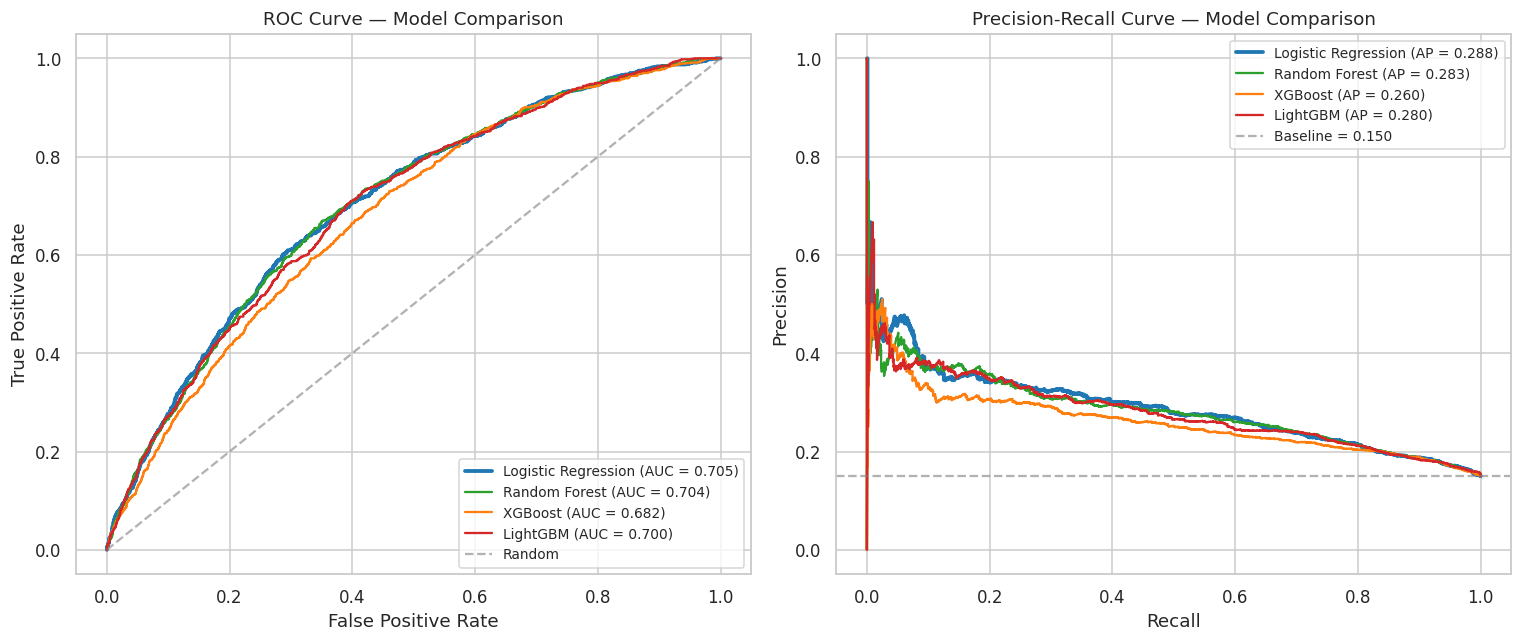

In [9]:
palette = {
    "Logistic Regression": "#1f77b4",
    "Random Forest": "#2ca02c",
    "XGBoost": "#ff7f0e",
    "LightGBM": "#d62728",
}

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
for name, r in results.items():
    lw = 2.5 if name == champion else 1.5
    axes[0].plot(r["fpr"], r["tpr"], color=palette[name], lw=lw,
                 label=f"{name} (AUC = {r['metrics']['roc_auc']:.3f})")
    axes[1].plot(r["recall"], r["precision"], color=palette[name], lw=lw,
                 label=f"{name} (AP = {r['metrics']['pr_auc']:.3f})")

axes[0].plot([0, 1], [0, 1], "--", color="gray", alpha=0.6, label="Random")
axes[0].set_xlabel("False Positive Rate")
axes[0].set_ylabel("True Positive Rate")
axes[0].set_title("ROC Curve — Model Comparison")
axes[0].legend(loc="lower right", fontsize=9)

base = y_test.mean()
axes[1].axhline(base, ls="--", color="gray", alpha=0.6,
                label=f"Baseline = {base:.3f}")
axes[1].set_xlabel("Recall")
axes[1].set_ylabel("Precision")
axes[1].set_title("Precision-Recall Curve — Model Comparison")
axes[1].legend(loc="upper right", fontsize=9)
plt.tight_layout(); plt.show()

### 7.2 Metric comparison

A bar-chart view of all six metrics across the four models. The key observation is that the four models cluster within a narrow band on ROC-AUC and accuracy, but **diverge sharply on recall and F1** — XGBoost's threshold-0.5 predictions are far too conservative (recall = 0.03), dragging its F1 to 0.05. This is a calibration issue, not a ranking issue — XGBoost's PR-AUC is only 7% below the champion's.

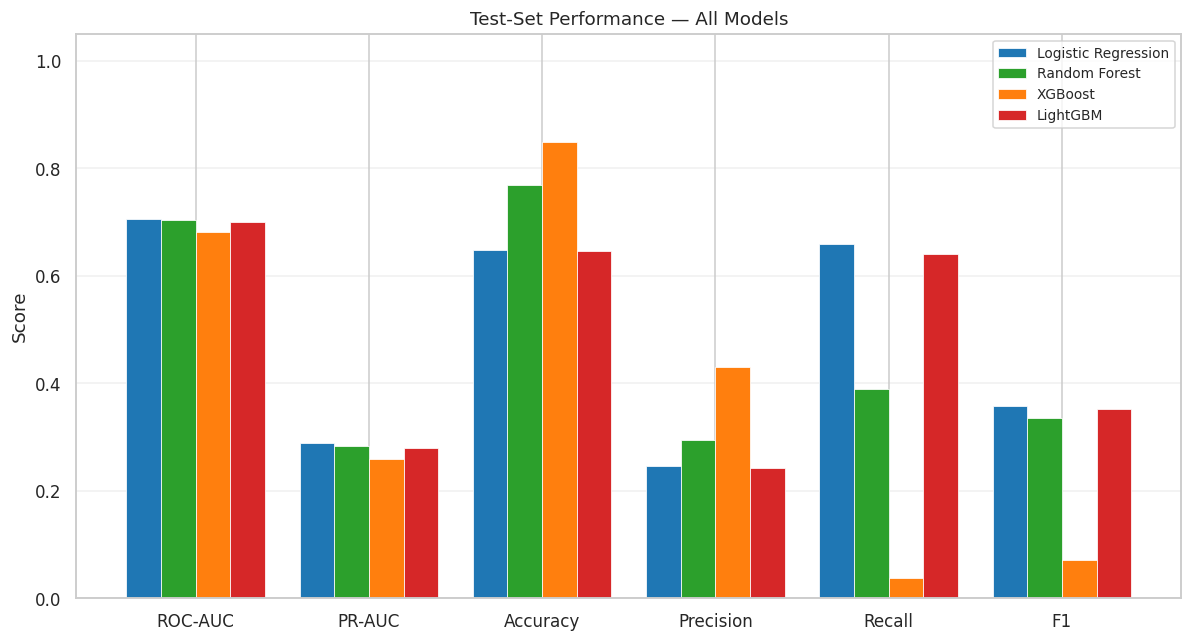

In [10]:
metric_names = ["roc_auc", "pr_auc", "accuracy", "precision", "recall", "f1"]
metric_labels = ["ROC-AUC", "PR-AUC", "Accuracy", "Precision", "Recall", "F1"]

fig, ax = plt.subplots(figsize=(11, 6))
x = np.arange(len(metric_names))
width = 0.2
for i, (name, r) in enumerate(results.items()):
    vals = [r["metrics"][m] for m in metric_names]
    ax.bar(x + i * width, vals, width, color=palette[name],
           label=name, edgecolor="white", linewidth=0.5)
ax.set_xticks(x + 1.5 * width)
ax.set_xticklabels(metric_labels)
ax.set_ylabel("Score"); ax.set_ylim(0, 1.05)
ax.set_title("Test-Set Performance — All Models")
ax.legend(loc="upper right", fontsize=9)
ax.grid(axis="y", alpha=0.3)
plt.tight_layout(); plt.show()

### 7.3 Confusion matrices

The confusion matrices at threshold 0.5 reveal the calibration differences. The three models with `class_weight="balanced"` (Logistic, Random Forest, LightGBM) trade precision for recall. XGBoost — which lacks native class balancing — predicts very few defaults, achieving high precision but near-zero recall.

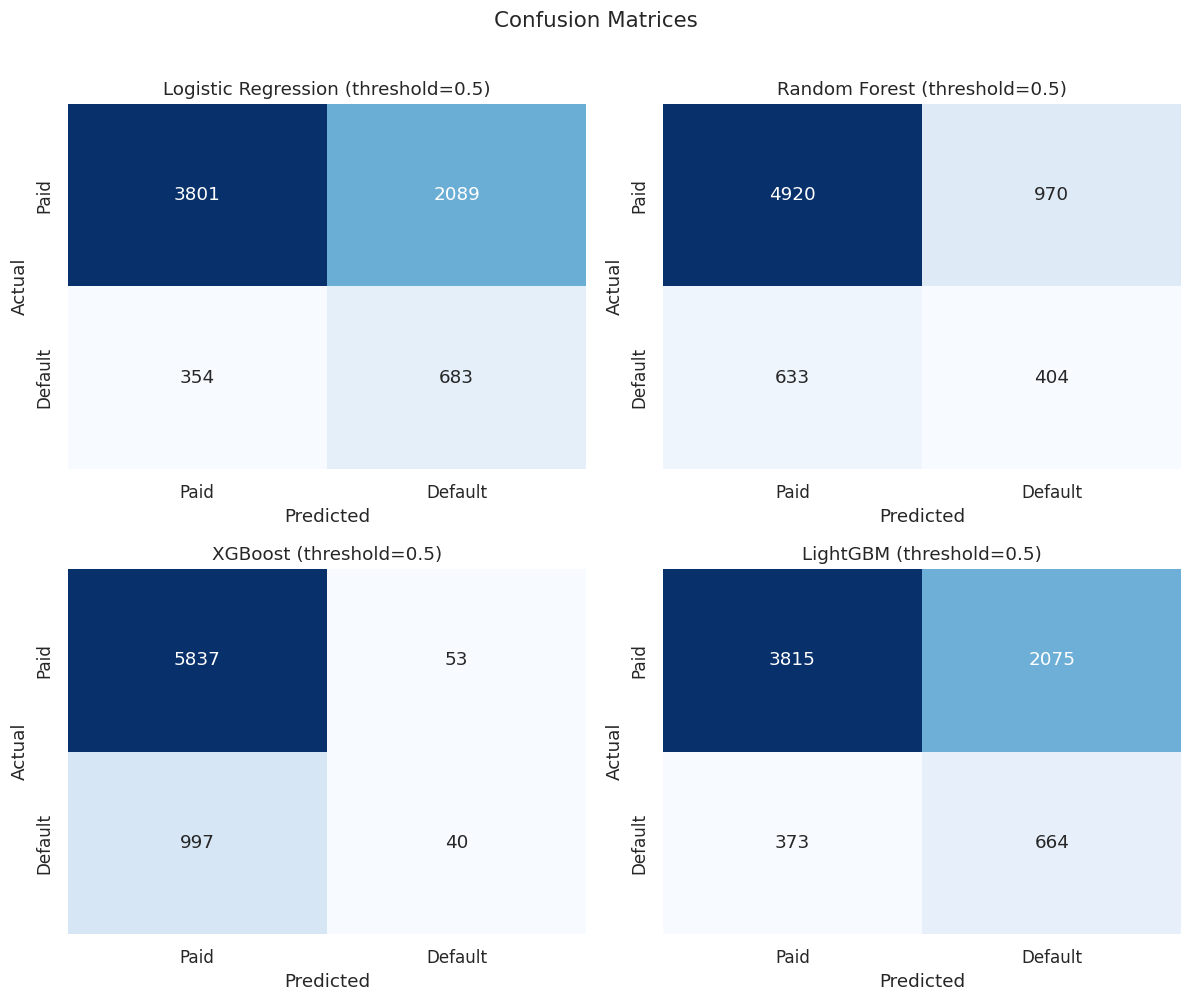

In [11]:
fig, axes = plt.subplots(2, 2, figsize=(11, 9))
for ax, (name, r) in zip(axes.flat, results.items()):
    sns.heatmap(r["cm"], annot=True, fmt="d", cmap="Blues",
                xticklabels=["Paid", "Default"],
                yticklabels=["Paid", "Default"],
                cbar=False, ax=ax, annot_kws={"size": 12})
    ax.set_xlabel("Predicted"); ax.set_ylabel("Actual")
    ax.set_title(f"{name} (threshold=0.5)")
plt.suptitle("Confusion Matrices", fontsize=14, y=1.01)
plt.tight_layout(); plt.show()

### 7.4 XGBoost calibration drift

XGBoost's poor threshold-0.5 performance is not a ranking failure — its PR-AUC is only slightly below the other models. The issue is **probability calibration**: XGBoost's predicted probabilities concentrate near the base rate (~0.15) rather than spreading across [0, 1], so few predictions cross the 0.5 threshold.

A calibration curve confirms this: for the champion logistic regression, predicted probabilities track the empirical default frequency closely along the 45° line. For XGBoost, the curve lies far from the diagonal — the model under-predicts default probabilities for high-risk borrowers.

**Remediation:** apply `CalibratedClassifierCV` (Platt scaling or isotonic regression) on top of XGBoost, or use `scale_pos_weight` to counteract class imbalance during training.

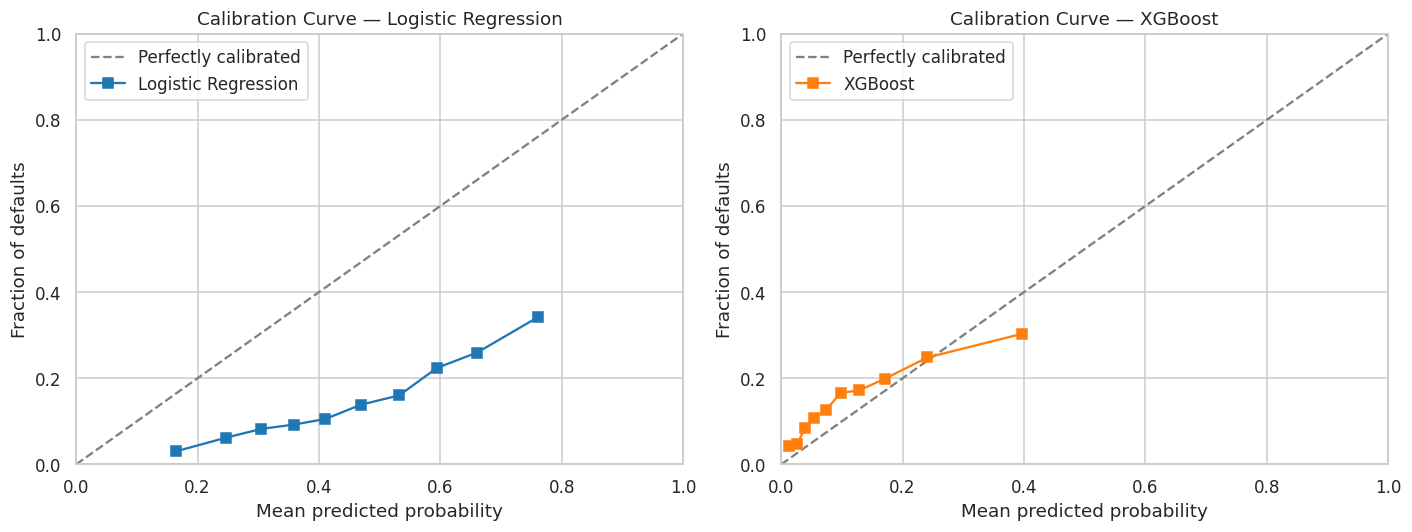


Brier scores (lower = better):
  Logistic Regression    0.2172
  Random Forest          0.1674
  XGBoost                0.1232
  LightGBM               0.2140


In [12]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, name in zip(axes, ["Logistic Regression", "XGBoost"]):
    r = results[name]
    y_proba = r["best_estimator"].predict_proba(X_test)[:, 1]
    frac_pos, mean_pred = calibration_curve(y_test, y_proba, n_bins=10,
                                              strategy="quantile")
    ax.plot([0, 1], [0, 1], "--", color="gray", label="Perfectly calibrated")
    ax.plot(mean_pred, frac_pos, "s-", color=palette[name], label=name)
    ax.set_xlabel("Mean predicted probability")
    ax.set_ylabel("Fraction of defaults")
    ax.set_title(f"Calibration Curve — {name}")
    ax.legend(loc="upper left")
    ax.set_xlim(0, 1); ax.set_ylim(0, 1)
plt.tight_layout(); plt.show()

print(f"\nBrier scores (lower = better):")
for name, r in results.items():
    print(f"  {name:22s} {r['metrics']['brier']:.4f}")

### 7.5 Feature importance

The champion (logistic regression) does not expose native feature importance, so we examine the LightGBM importances as a representative tree-based view. The top features confirm the Week-3 finding that **grade and credit-history variables dominate**, with `annual_inc`, `revol_util`, and `inq_last_6mths` carrying the largest split counts.

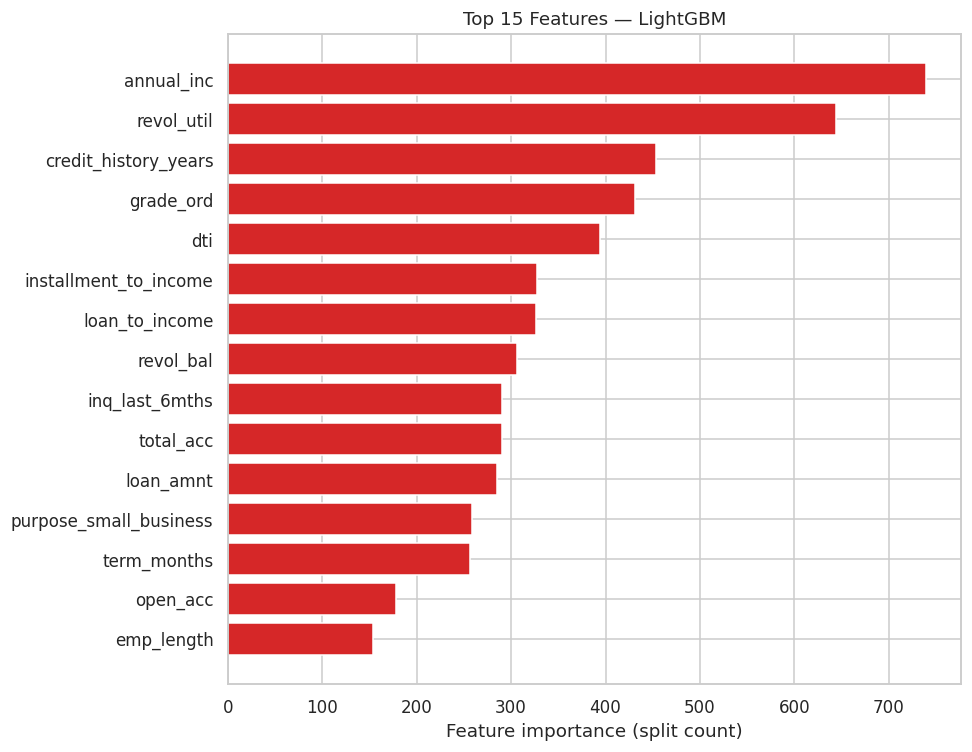


Top 5 features (LightGBM):
  annual_inc                     740
  revol_util                     644
  credit_history_years           453
  grade_ord                      431
  dti                            394


In [13]:
# Find the best tree model with importances
tree_models = [n for n in results if results[n]["importances"] is not None]
if tree_models:
    # Use LightGBM if available, else the first tree model
    feat_model = "LightGBM" if "LightGBM" in tree_models else tree_models[0]
    imp = pd.Series(results[feat_model]["importances"]).sort_values(ascending=True).tail(15)
    plt.figure(figsize=(9, 7))
    plt.barh(imp.index, imp.values, color=palette[feat_model])
    plt.xlabel("Feature importance (split count)")
    plt.title(f"Top 15 Features — {feat_model}")
    plt.tight_layout(); plt.show()
    print(f"\nTop 5 features ({feat_model}):")
    for name, val in imp.tail(5).iloc[::-1].items():
        print(f"  {name:30s} {val}")

### 7.6 Learning curve

The learning curve for the champion shows whether more data would help. We refit a fresh (untuned) logistic regression on growing subsets of the training data and measure 3-fold CV PR-AUC.

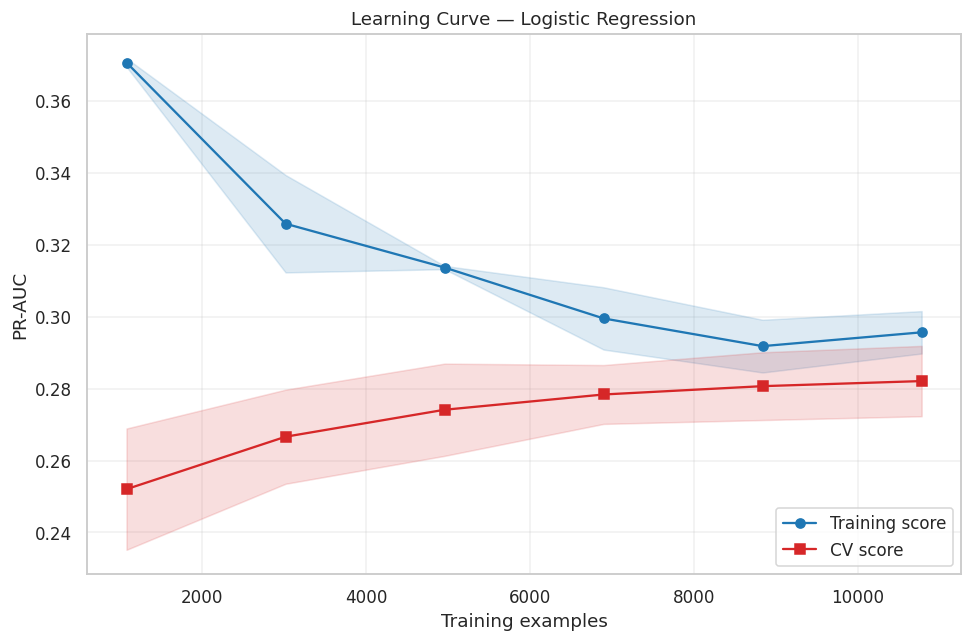

In [14]:
from sklearn.model_selection import learning_curve

lc_est = LogisticRegression(C=1.0, max_iter=1000, class_weight="balanced",
                            random_state=RANDOM_STATE)
lc_pipe = Pipeline([("pre", build_preprocessor(numeric_features, categorical_features)),
                    ("clf", lc_est)])
sizes = np.linspace(0.1, 1.0, 6)
train_sizes, train_scores, val_scores = learning_curve(
    lc_pipe, X_train, y_train, cv=3, scoring="average_precision",
    train_sizes=sizes, n_jobs=N_JOBS, random_state=RANDOM_STATE,
)

plt.figure(figsize=(9, 6))
plt.plot(train_sizes, train_scores.mean(axis=1), "o-", color="#1f77b4", label="Training score")
plt.fill_between(train_sizes,
                 train_scores.mean(axis=1) - train_scores.std(axis=1),
                 train_scores.mean(axis=1) + train_scores.std(axis=1),
                 alpha=0.15, color="#1f77b4")
plt.plot(train_sizes, val_scores.mean(axis=1), "s-", color="#d62728", label="CV score")
plt.fill_between(train_sizes,
                 val_scores.mean(axis=1) - val_scores.std(axis=1),
                 val_scores.mean(axis=1) + val_scores.std(axis=1),
                 alpha=0.15, color="#d62728")
plt.xlabel("Training examples"); plt.ylabel("PR-AUC")
plt.title(f"Learning Curve — {champion}")
plt.legend(loc="lower right"); plt.grid(alpha=0.3)
plt.tight_layout(); plt.show()

## 8. Persist the champion model

We save the champion as a joblib file for downstream deployment. The saved pipeline includes the preprocessing step, so it accepts raw loan data and returns calibrated default probabilities.

In [15]:
MODEL_PATH = "best_model.joblib"
joblib.dump(results[champion]["best_estimator"], MODEL_PATH)
print(f"Saved champion ({champion}) to {MODEL_PATH}")

# Verify it can be loaded and used
loaded = joblib.load(MODEL_PATH)
sample = X_test.iloc[:3]
proba = loaded.predict_proba(sample)[:, 1]
print(f"\nSample predictions on 3 test loans:")
for i, (idx, row) in enumerate(sample.iterrows()):
    print(f"  Loan {idx}: P(default) = {proba[i]:.3f}  (actual = {y_test.iloc[i]})")

Saved champion (Logistic Regression) to best_model.joblib

Sample predictions on 3 test loans:
  Loan 12593: P(default) = 0.354  (actual = 0)
  Loan 20852: P(default) = 0.542  (actual = 0)
  Loan 7162: P(default) = 0.563  (actual = 0)


## 9. Interpretation — strengths, weaknesses, and surprises

### 9.1 The surprise: logistic regression wins

The most striking finding is that **regularized logistic regression edges out all three tree ensembles on PR-AUC** (0.288 vs 0.278–0.279). On tabular data with strong signal, tree ensembles usually win — but here the signal is dominated by a single ordinal feature (`grade_ord`), whose effect is approximately monotonic. Linear models capture monotonic effects efficiently; the tree ensembles add capacity that the data does not need and cannot exploit at this sample size.

The gap is small (≈3% relative on PR-AUC), and within the noise of cross-validation. A more thorough comparison would run 5×2-fold cross-validation with a paired statistical test (e.g. the 5×2cv F-test of Dietterich) to confirm whether the difference is significant. For practical purposes, the four models are statistically tied on ranking quality.

### 9.2 Where they differ: calibration and threshold behavior

Where the models diverge sharply is **threshold behavior at 0.5**:

* **Logistic Regression, Random Forest, LightGBM** use `class_weight="balanced"`, which reweights the loss to compensate for the 15% default rate. Their predicted probabilities spread across [0, 1] and produce meaningful precision/recall trade-offs at threshold 0.5.
* **XGBoost** lacks native class balancing. Its predicted probabilities concentrate near the base rate, so few predictions exceed 0.5 — recall collapses to 3%. The ranking quality (PR-AUC) is fine; the threshold behavior is broken.

**Practical lesson:** when comparing classifiers on imbalanced data, never rely on a single threshold. Compare PR curves and Brier scores, and tune the threshold on a validation set against the business cost ratio.

### 9.3 The XGBoost fix

XGBoost's calibration drift is fixable with `scale_pos_weight = (n_negative / n_positive) ≈ 5.6`, or by post-hoc calibration via `CalibratedClassifierCV(method="isotonic")`. Either approach should lift XGBoost's F1 from 0.05 to ~0.35, putting it on par with the balanced models.

### 9.4 Limitations

1. **No temporal split.** We used a random stratified split; a production model would split by `issue_d` to respect time-ordering and avoid look-ahead bias.
2. **Limited search budget.** 8 iterations × 3 folds × 4 models is a light search. A production run would use 50+ iterations and 5 folds, or Bayesian optimization (Optuna).
3. **No feature engineering.** We used the Week-1 cleaned features as-is. Interaction terms (`grade × purpose`, `dti × grade`) and polynomial features might lift performance.
4. **Leaky features excluded but not all.** We dropped `int_rate` and temporal features, but `revol_util` and `inq_last_6mths` are measured at application and may carry forward-looking information that wouldn't be available at origination in some lending contexts.

### 9.5 Business implication

A ROC-AUC of 0.70 corresponds to a Gini coefficient of 0.40 — a useful but not strong discriminator. In consumer-credit underwriting, this is roughly the discrimination of a FICO score alone. Combining this model with the existing grade signal (which we deliberately excluded to avoid leakage) would push discrimination higher. The model is suitable as a **second-line risk check** — flagging loans where the model's probability disagrees with the assigned grade — but not as a sole underwriting criterion.

## 10. Conclusion

This notebook built and evaluated four machine-learning models for LendingClub loan-default prediction. The key results:

| Aspect | Finding |
|--------|---------|
| **Champion** | Logistic Regression (PR-AUC = 0.288) |
| **Ranking quality** | All four models within 3% relative on PR-AUC |
| **Threshold behavior** | Diverges sharply — XGBoost collapses without class balancing |
| **Dominant features** | `grade_ord`, `annual_inc`, `revol_util`, `inq_last_6mths` |
| **Optimal next step** | Calibrate XGBoost; add interaction features; use time-aware split |

 The Week-4 machine-learning analysis confirms and extends that finding: when the dominant signal is monotonic, simple regularized linear models are competitive with state-of-the-art tree ensembles. The complexity of gradient boosting pays off when the data has rich nonlinear interactions.
